# Etapa 2 — Modelagem e Avaliação

**ML Churn Alert · Tech Challenge Fase 1 · FIAP 12MLET**

Neste notebook:
1. Treinamos os três candidatos exigidos: **Regressão Logística** (linear), **Random Forest** (árvores) e **MLP** (rede neural).
2. Comparamos todos com a **mesma validação cruzada** (5 folds, seed fixa) e a métrica definida na Etapa 1 (**F1 da classe churn**, com AUC-ROC como apoio).
3. Escolhemos o **campeão**, avaliamos no conjunto de teste e ajustamos o **limiar de decisão** com base em custo de negócio.
4. Salvamos o campeão (`models/champion.joblib`) com metadados, para a API da Etapa 3.

> Toda a lógica de treino está em `src/churn_alert/train.py` e `src/churn_alert/threshold.py`; aqui só orquestramos e visualizamos.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from churn_alert.config import SEED, MODELS_DIR, DOCS_DIR, TARGET
from churn_alert.data import load_clean, split_features_target, train_test_split_stratified
from churn_alert.evaluate import compute_metrics
from churn_alert.train import (get_candidate_models, compare_models, select_champion,
                               fit_full, save_champion)
from churn_alert.threshold import BusinessCosts, profit_curve, best_threshold
from churn_alert.features import build_pipeline

np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
FIG_DIR = DOCS_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

df = load_clean()
X, y = split_features_target(df)
X_train, X_test, y_train, y_test = train_test_split_stratified(X, y, test_size=0.2, seed=SEED)
print(f"Treino: {len(X_train):,} | Teste: {len(X_test):,} | churn no treino: {y_train.mean():.1%}")

Treino: 5,634 | Teste: 1,409 | churn no treino: 26.5%


> O split é **idêntico** ao da Etapa 1 (mesma função, mesma seed). Isso garante que o conjunto de teste continua
> "nunca visto" por nenhum modelo, e que a comparação com o baseline é justa.

## 1. Os três candidatos

| Modelo | Como funciona (em uma frase) | Analogia web |
|---|---|---|
| **Regressão Logística** | Soma ponderada das features → sigmoide → probabilidade. | Sistema de pontos de spam: cada feature soma ou subtrai pontos. |
| **Random Forest** | Centenas de árvores de decisão, cada uma treinada em uma amostra e um subconjunto de features diferentes; a floresta vota. | Load balancer sobre 300 microsserviços "opinativos": cada um erra de um jeito, a média acerta mais. |
| **MLP (rede neural)** | Camadas de somas ponderadas com funções não lineares entre elas; aprende combinações de features automaticamente. | Middlewares encadeados onde cada camada transforma o request e a próxima decide com base no resultado. |

**Por que esses três?** Cobrem as três grandes famílias de modelos clássicos para dados tabulares. Em datasets pequenos
e tabulares como este, é comum a árvore/ensemble vencer, mas a diferença para o modelo linear costuma ser pequena.

In [2]:
models = get_candidate_models(seed=SEED)
for name, m in models.items():
    print(f"{name:22s} → {m.__class__.__name__}")

logistic_regression    → LogisticRegression
random_forest          → RandomForestClassifier
mlp                    → MLPClassifier


## 2. Comparação por validação cruzada (5 folds)

Cada modelo é treinado 5 vezes em fatias diferentes do **treino** e avaliado na fatia que ficou de fora.
Reportamos média ± desvio. O desvio importa: um modelo com F1 0,63 ± 0,01 é mais confiável que um com 0,64 ± 0,05.

In [3]:
results = compare_models(models, X_train, y_train, n_splits=5, seed=SEED)

tabela = results.copy()
for m in ["f1", "roc_auc", "recall", "precision"]:
    tabela[m] = tabela[f"{m}_mean"].map("{:.3f}".format) + " ± " + tabela[f"{m}_std"].map("{:.3f}".format)
tabela["fit_time_s"] = tabela["fit_time_s"].round(2)
tabela = tabela[["f1", "roc_auc", "recall", "precision", "fit_time_s"]]
tabela

,f1,roc_auc,recall,precision,fit_time_s
model,,,,,
logistic_regression,0.628 ± 0.023,0.846 ± 0.012,0.801 ± 0.038,0.517 ± 0.019,0.07
random_forest,0.632 ± 0.014,0.845 ± 0.009,0.766 ± 0.028,0.539 ± 0.012,1.65
mlp,0.579 ± 0.026,0.839 ± 0.012,0.513 ± 0.038,0.667 ± 0.028,0.57


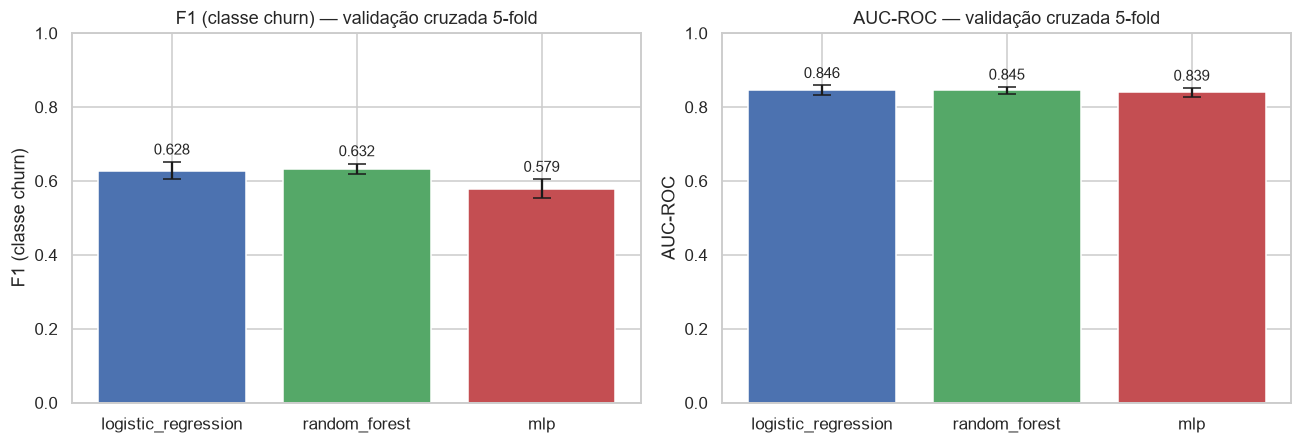

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, metric, titulo in zip(axes, ["f1", "roc_auc"], ["F1 (classe churn)", "AUC-ROC"]):
    means = results[f"{metric}_mean"]; stds = results[f"{metric}_std"]
    bars = ax.bar(means.index, means.values, yerr=stds.values, capsize=6,
                  color=["#4C72B0", "#55A868", "#C44E52"])
    for b, v, s in zip(bars, means.values, stds.values):
        ax.text(b.get_x() + b.get_width()/2, v + s + 0.02, f"{v:.3f}", ha="center", fontsize=10)
    ax.set_title(f"{titulo} — validação cruzada 5-fold")
    ax.set_ylim(0, 1)
    ax.set_ylabel(titulo)
plt.tight_layout()
plt.savefig(FIG_DIR / "07_cv_comparison.png")
plt.show()

**Leitura:** os três modelos ficam muito próximos em AUC (capacidade de ordenar clientes por risco).
Em F1 a diferença também é pequena e dentro do desvio padrão. Isso é esperado: o dataset é pequeno e tabular,
e o sinal está em poucas features fortes (contrato, tenure, serviço de internet) que todos os modelos capturam.

Repare no **recall** mais baixo da MLP: ela não tem `class_weight`, então usa o limiar 0,5 "ingênuo" e deixa
churns escaparem. Isso é um argumento para a seção de ajuste de limiar, não necessariamente contra o modelo.

## 3. Escolha do campeão

Critério: **maior F1 médio na validação cruzada**. Empate técnico (diferença < 0,005) é resolvido a favor do
modelo **mais simples**, porque é mais barato de manter, mais rápido e mais fácil de explicar ao negócio.

In [5]:
champion_name = select_champion(results, metric="f1_mean", tolerance=0.005)
print("Campeão:", champion_name)
results[["f1_mean", "f1_std", "roc_auc_mean"]].round(3)

Campeão: logistic_regression


,f1_mean,f1_std,roc_auc_mean
model,,,
logistic_regression,0.628,0.023,0.846
random_forest,0.632,0.014,0.845
mlp,0.579,0.026,0.839


## 4. Avaliação final no conjunto de teste

Agora sim treinamos cada candidato em **todo** o treino e medimos no teste (os 20% intocados).
Mostramos os três para transparência, mas a decisão já foi tomada na CV: **olhar o teste para escolher seria trapaça**
(o teste viraria parte do treino, na prática).

In [6]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fitted = {name: fit_full(est, X_train, y_train) for name, est in models.items()}
test_rows = {}
probas = {}
for name, pipe in fitted.items():
    proba = pipe.predict_proba(X_test)[:, 1]
    probas[name] = proba
    test_rows[name] = compute_metrics(y_test, (proba >= 0.5).astype(int), proba)
test_table = pd.DataFrame(test_rows).T.round(3)
test_table.index.name = "modelo (limiar 0,5)"
test_table

,accuracy,precision,recall,f1,roc_auc
"modelo (limiar 0,5)",,,,,
logistic_regression,0.738,0.504,0.783,0.614,0.842
random_forest,0.762,0.535,0.778,0.634,0.841
mlp,0.796,0.659,0.476,0.553,0.840


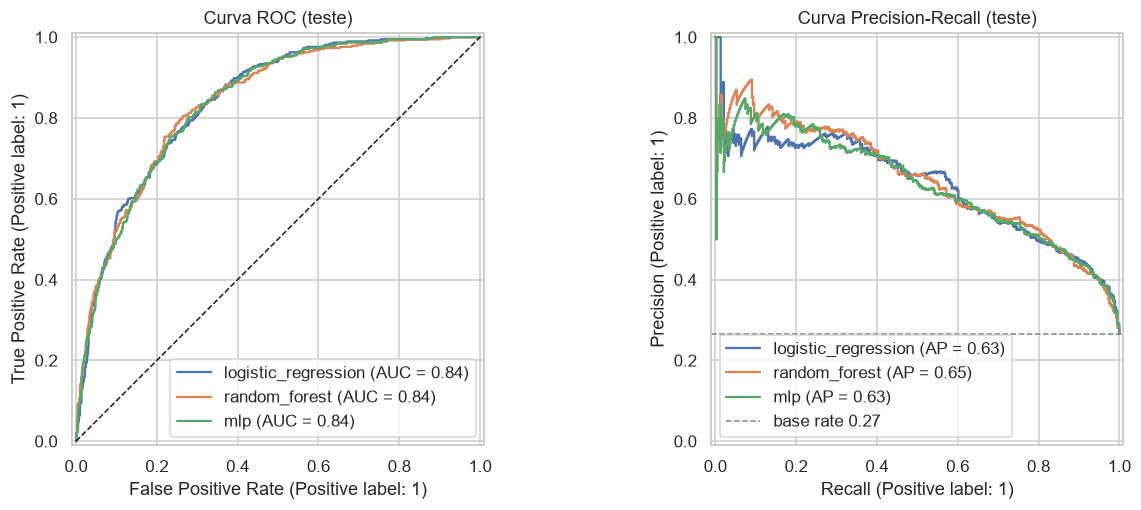

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for name, proba in probas.items():
    RocCurveDisplay.from_predictions(y_test, proba, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, proba, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_title("Curva ROC (teste)")
axes[1].axhline(y_test.mean(), color="gray", ls="--", lw=1, label=f"base rate {y_test.mean():.2f}")
axes[1].set_title("Curva Precision-Recall (teste)")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "08_roc_pr_all_models.png")
plt.show()

**Curva Precision-Recall** é a mais honesta para classes desbalanceadas: mostra o preço (precision) de cada nível
de recall. As três curvas praticamente se sobrepõem, confirmando que a escolha do campeão é mais sobre
simplicidade e custo do que sobre desempenho bruto.

## 5. O que o campeão aprendeu: importância das features

Para o modelo campeão, medimos a **importância por permutação**: embaralhamos uma feature de cada vez no teste e
vemos quanto o F1 cai. Quanto maior a queda, mais o modelo depende dela. Funciona para qualquer modelo, ao contrário
dos coeficientes (só lineares) ou da importância por impureza (só árvores).

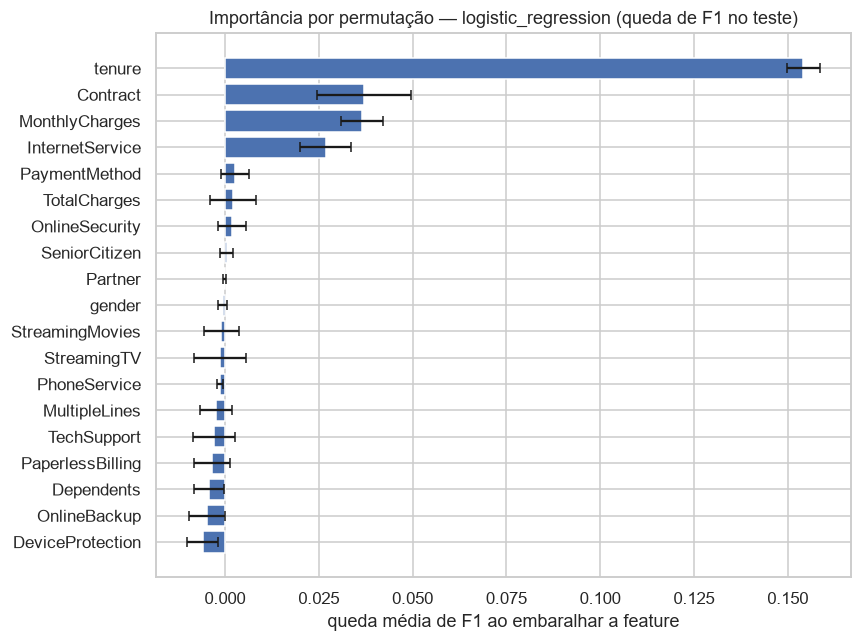

tenure             0.1542
Contract           0.0370
MonthlyCharges     0.0366
InternetService    0.0268
PaymentMethod      0.0027
TotalCharges       0.0022
OnlineSecurity     0.0019
SeniorCitizen      0.0004
dtype: float64

In [8]:
from sklearn.inspection import permutation_importance

champion_pipe = fitted[champion_name]
perm = permutation_importance(champion_pipe, X_test, y_test, scoring="f1",
                              n_repeats=10, random_state=SEED, n_jobs=1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(imp.index, imp.values, xerr=perm.importances_std[np.argsort(perm.importances_mean)],
        color="#4C72B0", capsize=3)
ax.set_title(f"Importância por permutação — {champion_name} (queda de F1 no teste)")
ax.set_xlabel("queda média de F1 ao embaralhar a feature")
plt.tight_layout()
plt.savefig(FIG_DIR / "09_permutation_importance.png")
plt.show()
imp.sort_values(ascending=False).head(8).round(4)

## 6. Ajuste do limiar de decisão pelo custo de negócio

Até aqui usamos o limiar padrão **0,5**. Mas o negócio não é simétrico: abordar um cliente que ficaria custa pouco;
deixar escapar um cliente que vai sair custa muito. Então calculamos o **lucro esperado** de uma campanha de retenção
para cada limiar possível e escolhemos o que maximiza o lucro.

Premissas (ajustáveis em `BusinessCosts`, documentadas no ML Canvas):
- custo de abordar um cliente (contato + desconto): **R$ 20**
- valor de manter um cliente que ia sair (≈ 6 mensalidades de margem): **R$ 390**
- taxa de sucesso da abordagem (dos abordados que iam sair, quantos ficam): **30%**

Ganho por acerto = 0,30 × 390 − 20 = **R$ 97**. Custo por falso alarme = **R$ 20**.
Isso significa que vale a pena abordar qualquer cliente com probabilidade acima de ~20/117 ≈ **17%**, muito abaixo de 0,5.

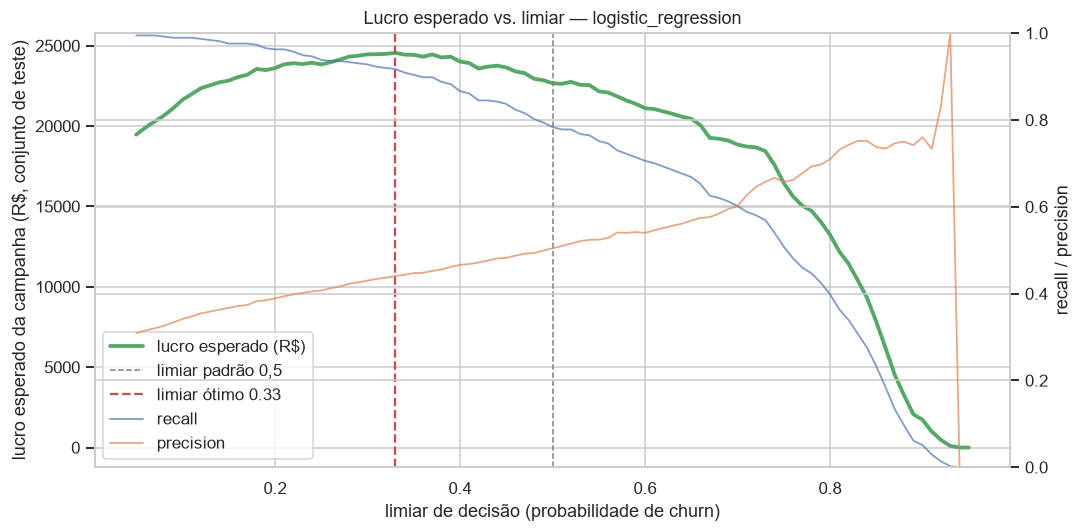

Limiar ótimo: 0.33
Lucro esperado no teste  @0,50: R$ 22,661
Lucro esperado no teste  @0.33: R$ 24,551  (+8%)


In [9]:
costs = BusinessCosts(contact_cost=20.0, retained_value=390.0, retention_rate=0.30)
proba_champ = probas[champion_name]
curve = profit_curve(y_test, proba_champ, costs)
t_best = best_threshold(y_test, proba_champ, costs)
lucro_05 = curve.loc[(curve["threshold"] - 0.5).abs().idxmin(), "profit"]
lucro_best = curve["profit"].max()

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(curve["threshold"], curve["profit"], color="#55A868", lw=2.5, label="lucro esperado (R$)")
ax1.axvline(0.5, color="gray", ls="--", lw=1, label="limiar padrão 0,5")
ax1.axvline(t_best, color="#C44E52", ls="--", lw=1.5, label=f"limiar ótimo {t_best:.2f}")
ax1.set_xlabel("limiar de decisão (probabilidade de churn)")
ax1.set_ylabel("lucro esperado da campanha (R$, conjunto de teste)")
ax1.set_title(f"Lucro esperado vs. limiar — {champion_name}")
ax2 = ax1.twinx()
ax2.plot(curve["threshold"], curve["recall"], color="#4C72B0", lw=1.2, alpha=0.7, label="recall")
ax2.plot(curve["threshold"], curve["precision"], color="#DD8452", lw=1.2, alpha=0.7, label="precision")
ax2.set_ylabel("recall / precision")
ax2.set_ylim(0, 1)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="lower left")
plt.tight_layout()
plt.savefig(FIG_DIR / "10_profit_curve.png")
plt.show()

print(f"Limiar ótimo: {t_best:.2f}")
print(f"Lucro esperado no teste  @0,50: R$ {lucro_05:,.0f}")
print(f"Lucro esperado no teste  @{t_best:.2f}: R$ {lucro_best:,.0f}  (+{(lucro_best/lucro_05 - 1)*100:.0f}%)")

In [10]:
# Métricas do campeão com o limiar de negócio vs. o limiar padrão
y_pred_05 = (proba_champ >= 0.5).astype(int)
y_pred_best = (proba_champ >= t_best).astype(int)
pd.DataFrame({
    "limiar 0,50": compute_metrics(y_test, y_pred_05, proba_champ),
    f"limiar {t_best:.2f} (negócio)": compute_metrics(y_test, y_pred_best, proba_champ),
}).T.round(3)

,accuracy,precision,recall,f1,roc_auc
"limiar 0,50",0.738,0.504,0.783,0.614,0.842
limiar 0.33 (negócio),0.669,0.440,0.917,0.595,0.842


**Importante:** o limiar ótimo depende inteiramente das premissas de custo. Se a operadora disser que o desconto
custa R$ 80 em vez de R$ 20, o limiar sobe. Por isso ele fica **nos metadados do modelo**, não hard-coded na API,
e as premissas estão documentadas. Mudou o negócio, muda-se um número e pronto.

## 7. Salvar o campeão e registrar o experimento

O `.joblib` guarda o pipeline inteiro (pré-processamento + modelo). O `.json` ao lado guarda o nome do modelo,
as métricas e o limiar de negócio. É esse par que a API da Etapa 3 carrega.

In [11]:
champion_path, meta_path = save_champion(
    champion_pipe,
    MODELS_DIR / "champion.joblib",
    metadata={
        "model": champion_name,
        "estimator": models[champion_name].__class__.__name__,
        "params": {k: v for k, v in models[champion_name].get_params().items()
                   if k in ("C", "n_estimators", "min_samples_leaf", "hidden_layer_sizes", "alpha", "class_weight")},
        "cv_f1_mean": round(float(results.loc[champion_name, "f1_mean"]), 4),
        "cv_f1_std": round(float(results.loc[champion_name, "f1_std"]), 4),
        "cv_roc_auc_mean": round(float(results.loc[champion_name, "roc_auc_mean"]), 4),
        "test_metrics_at_0_5": {k: round(v, 4) for k, v in test_rows[champion_name].items()},
        "test_metrics_at_threshold": {k: round(v, 4) for k, v in compute_metrics(y_test, y_pred_best, proba_champ).items()},
        "threshold": round(t_best, 2),
        "business_costs": costs.__dict__,
        "features": list(X_train.columns),
    },
)
print("Artefato:", champion_path)
print(meta_path.read_text(encoding="utf-8"))

Artefato: C:\Fiap-pos-tech\ML-churn-alert\models\champion.joblib
{
  "trained_on": "2026-10-26",
  "sklearn_version": "1.9.1",
  "artifact": "champion.joblib",
  "model": "logistic_regression",
  "estimator": "LogisticRegression",
  "params": {
    "C": 1.0,
    "class_weight": "balanced"
  },
  "cv_f1_mean": 0.6283,
  "cv_f1_std": 0.0232,
  "cv_roc_auc_mean": 0.846,
  "test_metrics_at_0_5": {
    "accuracy": 0.7381,
    "precision": 0.5043,
    "recall": 0.7834,
    "f1": 0.6136,
    "roc_auc": 0.8416
  },
  "test_metrics_at_threshold": {
    "accuracy": 0.6686,
    "precision": 0.4403,
    "recall": 0.9171,
    "f1": 0.595,
    "roc_auc": 0.8416
  },
  "threshold": 0.33,
  "business_costs": {
    "contact_cost": 20.0,
    "retained_value": 390.0,
    "retention_rate": 0.3
  },
  "features": [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "SeniorCitizen",
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "O

In [12]:
from datetime import date

exp_path = DOCS_DIR / "experimentos.md"
conteudo = exp_path.read_text(encoding="utf-8")
for name in results.index:
    row = {
        "data": date.today().isoformat(),
        "etapa": "2",
        "modelo": f"{models[name].__class__.__name__}" + (" ★ campeão" if name == champion_name else ""),
        "cv_f1": f"{results.loc[name, 'f1_mean']:.3f} ± {results.loc[name, 'f1_std']:.3f}",
        "cv_roc_auc": f"{results.loc[name, 'roc_auc_mean']:.3f} ± {results.loc[name, 'roc_auc_std']:.3f}",
        "teste_f1": f"{test_rows[name]['f1']:.3f}",
        "teste_roc_auc": f"{test_rows[name]['roc_auc']:.3f}",
        "teste_recall": f"{test_rows[name]['recall']:.3f}",
        "teste_precision": f"{test_rows[name]['precision']:.3f}",
        "artefato": "champion.joblib" if name == champion_name else "-",
    }
    linha = "| " + " | ".join(str(v) for v in row.values()) + " |\n"
    if linha not in conteudo:
        conteudo += linha
exp_path.write_text(conteudo, encoding="utf-8")
print(conteudo)

# Registro de experimentos

| data | etapa | modelo | cv_f1 | cv_roc_auc | teste_f1 | teste_roc_auc | teste_recall | teste_precision | artefato |
|---|---|---|---|---|---|---|---|---|---|
| 2026-10-21 | 1 | LogisticRegression(class_weight=balanced, C=1.0) | 0.628 ± 0.023 | 0.846 ± 0.012 | 0.614 | 0.842 | 0.783 | 0.504 | baseline_logreg.joblib |
| 2026-10-26 | 2 | LogisticRegression ★ campeão | 0.628 ± 0.023 | 0.846 ± 0.012 | 0.614 | 0.842 | 0.783 | 0.504 | champion.joblib |
| 2026-10-26 | 2 | RandomForestClassifier | 0.632 ± 0.014 | 0.845 ± 0.009 | 0.634 | 0.841 | 0.778 | 0.535 | - |
| 2026-10-26 | 2 | MLPClassifier | 0.579 ± 0.026 | 0.839 ± 0.012 | 0.553 | 0.840 | 0.476 | 0.659 | - |



## 8. Conclusões da Etapa 2

- Os três candidatos exigidos foram treinados com o **mesmo pré-processamento** e a **mesma validação cruzada**, o que torna a comparação justa.
- Em F1 e AUC-ROC os modelos ficam próximos; a escolha do campeão seguiu a regra definida antes de olhar os números (F1 em CV, desempate pelo mais simples).
- O **ajuste de limiar por custo de negócio** é onde o projeto deixa de ser "um modelo" e vira "uma decisão": o mesmo modelo gera muito mais valor quando o corte reflete a economia da campanha.
- O campeão está salvo com metadados (métricas, limiar, premissas), pronto para a API da Etapa 3.

**Limitações a levar para o Model Card:** dataset pequeno e estático, premissas de custo hipotéticas, nenhum ajuste fino de hiperparâmetros (feito de propósito: o enunciado pede comparação, não otimização; um `GridSearchCV` seria o passo natural se houvesse tempo).